In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

# Visual identity used in every graph
Palette = ["#ebc334", "#bd1041", "#76d5de", '#6250d6', "#48e348"]
Tier_Order = ['hot desk', 'flex', 'dedicated desk', 'full time', 'private office']
Tier_Color = dict(zip(Tier_Order, Palette))
Graph_Color = ['#E7AA30', '#87cefa']
Edgecolor = ['#000000', '#FFFFFF']
Heatmap = ['PiYG', 'Blues']

Directory = '/Users/josemenezes/Faculdade/Projetos/Projeto DM/Data-Mining-Project/Dataset/'
acdc_dataset = pd.read_csv(Directory + 'acdc_dataset.csv', sep=';')

# Data Description

In [9]:
acdc_dataset.shape

(15465, 31)

In [10]:
acdc_dataset.head(3).T

,0,1,2
member_id,CW000001,CW000002,CW000003
age,38.0,38.0,43.0
gender,Female,Male,Male
industry,Information Technology,Information Technology,Education
country,Portugal,Portugal,DE
is_team_account,False,True,True
n_colleagues_on_account,0,2,1
plan_tier,flex,HOT_DESK,flex
plan_days_per_week,3,2,3
membership_start,2021-08-01,2023-11-24,2021-12-03


In [11]:
acdc_dataset.tail(3).T

,15462,15463,15464
member_id,CW003868,CW013132,CW015101
age,28.0,32.0,46.0
gender,Female,Female,Male
industry,Design & Creative,Legal,Information Technology
country,Portugal,Portugal,Portugal
is_team_account,True,False,False
n_colleagues_on_account,1,0,0
plan_tier,hot_desk,dedicated_desk,flex
plan_days_per_week,2,5,3
membership_start,2023-12-27,2021-08-28,2022-02-04


In [6]:
acdc_dataset.columns

Index(['member_id', 'age', 'gender', 'industry', 'country', 'is_team_account', 'n_colleagues_on_account', 'plan_tier', 'plan_days_per_week', 'membership_start', 'membership_end', 'last_badge_swipe',
       'days_since_last_visit', 'total_visits', 'avg_weekly_visits', 'entitled_visits_last_period', 'actual_visits_last_period', 'meeting_room_hours', 'event_space_hours', 'guest_passes_issued',
       'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes', 'uses_print', 'uses_mail_handling', 'uses_phone_booths', 'uses_day_passes', 'uses_storage', 'uses_bike_locker', 'n_renewals',
       'lifetime_value'],
      dtype='object')

In [ ]:
acdc_dataset.dtypes

member_id                      object
age                            object
gender                         object
industry                       object
country                        object
is_team_account                  bool
n_colleagues_on_account         int64
plan_tier                      object
plan_days_per_week              int64
membership_start               object
membership_end                 object
last_badge_swipe               object
days_since_last_visit           int64
total_visits                    int64
avg_weekly_visits              object
entitled_visits_last_period    object
actual_visits_last_period       int64
meeting_room_hours             object
event_space_hours              object
guest_passes_issued            object
uses_meeting_rooms               bool
uses_event_space                 bool
uses_guest_passes                bool
uses_print                      int64
uses_mail_handling               bool
uses_phone_booths                bool
uses_day_pas

In [ ]:
acdc_dataset.describe(include='all')

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
count,15465,14907,14935,15465,15035,15465,15465.000000,15360,15465.000000,15465,...,15465,15465,15465.000000,15465,15465,15465,15465,15465,15465.000000,14425
unique,15450,84,12,43,33,2,NaN,19,NaN,1539,...,2,2,NaN,2,2,2,2,2,NaN,11860
top,CW005845,34.0,Female,Information Technology,Portugal,False,NaN,flex,NaN,2021-01-01,...,False,False,NaN,False,False,False,False,False,NaN,0
freq,2,710,7414,3322,9959,11112,NaN,5182,NaN,560,...,13624,12651,NaN,11901,11469,12069,13169,15439,NaN,1725
mean,NaN,NaN,NaN,NaN,NaN,NaN,0.537019,NaN,3.387262,NaN,...,NaN,NaN,0.323052,NaN,NaN,NaN,NaN,NaN,1.005496,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,1.177668,NaN,1.458818,NaN,...,NaN,NaN,0.467658,NaN,NaN,NaN,NaN,NaN,1.353812,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,-1.000000,NaN,0.000000,NaN,...,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,-3.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,2.000000,NaN,...,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,3.000000,NaN,...,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,5.000000,NaN,...,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,2.000000,NaN


# Duplicates

In [ ]:
acdc_dataset.duplicated().sum()


15

In [ ]:
df = acdc_dataset.drop_duplicates()
acdc_dataset.shape

(15450, 31)

# Missing Values

In [ ]:
acdc_dataset.isna().sum()

member_id                         0
age                             557
gender                          530
industry                          0
country                         429
is_team_account                   0
n_colleagues_on_account           0
plan_tier                       105
plan_days_per_week                0
membership_start                  0
membership_end                    0
last_badge_swipe                  0
days_since_last_visit             0
total_visits                      0
avg_weekly_visits                 0
entitled_visits_last_period       0
actual_visits_last_period         0
meeting_room_hours             1295
event_space_hours                 0
guest_passes_issued            1269
uses_meeting_rooms                0
uses_event_space                  0
uses_guest_passes                 0
uses_print                        0
uses_mail_handling                0
uses_phone_booths                 0
uses_day_passes                   0
uses_storage                

In [ ]:
nulos = acdc_dataset.isnull().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
nulos

meeting_room_hours     1295
guest_passes_issued    1269
lifetime_value         1040
age                     557
gender                  530
country                 429
plan_tier               105
dtype: int64

In [ ]:
acdc_dataset.replace("", np.nan, inplace=True)

nulos = acdc_dataset.isnull().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
nulos

meeting_room_hours     1295
guest_passes_issued    1269
lifetime_value         1040
age                     557
gender                  530
country                 429
plan_tier               105
dtype: int64

# Cleaning

In [ ]:
acdc_dataset.dtypes

member_id                      object
age                            object
gender                         object
industry                       object
country                        object
is_team_account                  bool
n_colleagues_on_account         int64
plan_tier                      object
plan_days_per_week              int64
membership_start               object
membership_end                 object
last_badge_swipe               object
days_since_last_visit           int64
total_visits                    int64
avg_weekly_visits              object
entitled_visits_last_period    object
actual_visits_last_period       int64
meeting_room_hours             object
event_space_hours              object
guest_passes_issued            object
uses_meeting_rooms               bool
uses_event_space                 bool
uses_guest_passes                bool
uses_print                      int64
uses_mail_handling               bool
uses_phone_booths                bool
uses_day_pas

### Member_id

In [ ]:
df['member_id'].duplicated().sum() #checking for duplicates

0

### Age

In [ ]:
df['age'] = df['age'].astype(float) #changing age type

### Gender

In [ ]:
df['gender'].unique()

array(['Female', 'Male', 'F', 'Other', nan, ' Female', 'M', 'male',
       ' Male', 'other', ' Other', 'female', 'O'], dtype=object)

In [ ]:
gender_dict = {
    "F": "female",
    "M": "male",                #fixing gender labels
    "O": "Other"
               }

df['gender'] = df['gender'].replace(gender_dict)

df['gender'] = df['gender'].str.lower()

df['gender'] = df['gender'].str.strip()

df['gender'].unique()

array(['female', 'male', 'other', nan], dtype=object)

### Industry

In [ ]:
df['industry'].unique()

array(['Information Technology', 'Education', 'Legal', 'Health',
       'Unknown', 'Other', 'Consulting', 'Design & Creative',
       'information technology', 'Finance', 'Marketing & PR', 'EDUCATION',
       'DESIGN & CREATIVE', 'Marketing and PR', 'Real Estate', 'other',
       'consulting', 'MARKETING & PR', 'Information technology',
       'design & creative', 'LEGAL', 'marketing & pr',
       'INFORMATION TECHNOLOGY', 'health', 'Marketing/PR', 'CONSULTING',
       'unknown', 'Design/Creative', 'RealEstate', 'IT', 'Tech',
       'Marketing & Pr', 'OTHER', 'legal', 'finance', 'real estate',
       'education', 'Design and Creative', 'UNKNOWN', 'FINANCE',
       'REAL ESTATE', 'HEALTH', 'Real-Estate'], dtype=object)

In [ ]:
industry_dict = {
    "realestate": "real estate",
    "it": "information technology",
    "tech": "information technology"
}

s = (
    df['industry']
    .astype('string')
    .str.strip()
    .str.lower()
    .str.replace("/", " & ", regex=False)
    .str.replace(r"\band\b", "&", regex=True)
    .str.replace(r"[-_]", " ", regex=True)
    .str.replace(r"\s*&\s*", " & ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

df['industry'] = s.replace(industry_dict)
df['industry'].unique()


<StringArray>
['information technology',              'education',                  'legal',
                 'health',                'unknown',                  'other',
             'consulting',      'design & creative',                'finance',
         'marketing & pr',            'real estate']
Length: 11, dtype: string

### Country

In [ ]:
df['country'].unique()

array(['Portugal', 'DE', 'portugal', 'United Kingdom', 'Spain', 'Germany',
       'Netherlands', 'France', 'PT', 'Other (Europe)', 'Portucal', nan,
       'UK', 'Ireland', 'United kingdom', 'IE', 'portugal ',
       'Deutschland', 'ireland', 'germany', 'france', 'united kingdom',
       'other (europe)', 'U.K.', 'GB', 'ES', 'NL', 'España', 'Espana',
       'netherlands', 'spain', 'The Netherlands', 'FR', 'Holland'],
      dtype=object)

In [ ]:
country_dict = {
    'portucal': 'portugal',
    'pt': 'portugal',
    'de': 'germany',
    'deutschland': 'germany',
    'uk': 'united kingdom',
    'u.k.': 'united kingdom',
    'gb': 'united kingdom',
    'ie': 'ireland',
    'es': 'spain',
    'españa': 'spain',
    'espana': 'spain',
    'fr': 'france',
    'nl': 'netherlands',
    'the netherlands': 'netherlands',
    'holland': 'netherlands'
}

# Standardize spelling/case first so that all variants can be mapped consistently.
df['country'] = (
    df['country']
    .astype('string')
    .str.strip()
    .str.lower()
    .replace(country_dict)
)

df['country'].unique()


<StringArray>
[      'portugal',        'germany', 'united kingdom',          'spain',
    'netherlands',         'france', 'other (europe)',             <NA>,
        'ireland']
Length: 9, dtype: string

### Is_team_account

In [ ]:
df['is_team_account'].unique() # everything good

array([False,  True])

### Plan_tier

In [ ]:
df['plan_tier'].unique()

array(['flex', 'HOT_DESK', 'hot_desk', 'dedicated_desk', 'full_time',
       'private_office', 'Hot Desk', 'dedicateddesk', nan, 'FULL_TIME',
       'hotdesk', 'Flex', 'FLEX', 'fulltime', 'privateoffice',
       'Full Time', 'DEDICATED_DESK', 'Dedicated Desk', 'Private Office',
       'PRIVATE_OFFICE'], dtype=object)

In [ ]:
df['plan_tier'] = df['plan_tier'].str.lower()

df['plan_tier'] = df['plan_tier'].str.replace("_", " ")

plan_tier_dict = {
    "fulltime": "full time",
    "hotdesk": "hot desk",
    "privateoffice": "private office",
    "dedicateddesk": "dedicated desk"
}

df['plan_tier'] = df['plan_tier'].replace(plan_tier_dict)

df['plan_tier'].unique()

array(['flex', 'hot desk', 'dedicated desk', 'full time',
       'private office', nan], dtype=object)

### Membership_start_end Last_badge_swipe

In [ ]:
# Convert date fields to datetime so they can be checked and used consistently later.
date_columns = ['membership_start', 'membership_end', 'last_badge_swipe']
for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors='coerce')

# Some membership_end values precede membership_start (for example placeholder dates).
# They cannot represent a valid completed membership and are therefore treated as missing.
invalid_end_date = df['membership_end'] < df['membership_start']
acdc_dataset.loc[invalid_end_date, 'membership_end'] = pd.NaT

print(f'Invalid membership end dates set to missing: {invalid_end_date.sum()}')
df[date_columns].dtypes


Invalid membership end dates set to missing: 3922


membership_start    datetime64[ns]
membership_end      datetime64[ns]
last_badge_swipe    datetime64[ns]
dtype: object

### Avg_weekly_visits

In [ ]:
df['avg_weekly_visits'] = df['avg_weekly_visits'].astype(float)

### Entitled_visits_last_period

In [ ]:
df['entitled_visits_last_period'] = df['entitled_visits_last_period'].astype(float)

### Meeting_room_hours / Event_space_hours / Guest_passes_issued

In [ ]:
df['meeting_room_hours'] = df['meeting_room_hours'].astype(float)

df['event_space_hours'] = df['event_space_hours'].astype(float)

df['guest_passes_issued'] = df['guest_passes_issued'].astype(float)

### Uses_print

In [ ]:
df['uses_print'].unique()

array([0, 1], dtype=int64)

In [ ]:
df['uses_print'] = df['uses_print'].astype(bool)

In [ ]:
df[['uses_phone_booths', 'uses_day_passes']].dtypes

uses_phone_booths    bool
uses_day_passes      bool
dtype: object

### Lifetime_value

In [ ]:
df['lifetime_value'] = (
    df['lifetime_value']
    .str.replace("€", "", regex=False) # removing "€" and "," to convert to float for metrics
    .str.replace(",", "", regex=False)
    .str.strip()
    .astype(float)
)

# Information (cleaned Data)

In [ ]:
acdc_dataset.dtypes

member_id                              object
age                                   float64
gender                                 object
industry                       string[python]
country                        string[python]
is_team_account                          bool
n_colleagues_on_account                 int64
plan_tier                              object
plan_days_per_week                      int64
membership_start               datetime64[ns]
membership_end                 datetime64[ns]
last_badge_swipe               datetime64[ns]
days_since_last_visit                   int64
total_visits                            int64
avg_weekly_visits                     float64
entitled_visits_last_period           float64
actual_visits_last_period               int64
meeting_room_hours                    float64
event_space_hours                     float64
guest_passes_issued                   float64
uses_meeting_rooms                       bool
uses_event_space                  

In [ ]:
acdc_dataset.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
member_id,15450,15450,CW000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,14893.0,NaN,NaN,NaN,34.862687,1.0,29.0,34.0,40.0,149.0,10.39591
gender,14920,3,female,7858,NaN,NaN,NaN,NaN,NaN,NaN,NaN
industry,15450,11,information technology,3557,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,15021,8,portugal,10499,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_team_account,15450,2,False,11100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_colleagues_on_account,15450.0,NaN,NaN,NaN,0.537152,-1.0,0.0,0.0,1.0,9.0,1.177748
plan_tier,15345,5,flex,5449,NaN,NaN,NaN,NaN,NaN,NaN,NaN
plan_days_per_week,15450.0,NaN,NaN,NaN,3.386667,0.0,2.0,3.0,5.0,9.0,1.458691
membership_start,14813,NaN,NaN,NaN,2022-03-16 09:45:53.770337024,2021-01-01 00:00:00,2021-06-02 00:00:00,2022-01-07 00:00:00,2022-11-06 00:00:00,2023-12-30 00:00:00,NaN


# Exploratory Data Analysis and Visualizations

The following section explores the cleaned dataset from a segmentation perspective. The aim is not only to describe the members, but to identify differences in value, activity, plan usage and service engagement that may later help distinguish meaningful customer groups.

The analysis starts with broad distributions and then moves toward relationships between variables. Particular attention is given to variables that can separate low- and high-value members, light and intensive users, and members with different workspace needs.

## 1. Member age distribution

Age provides a basic view of the demographic composition of the member base. The histogram shows where most members are concentrated, while the boxplot makes unusually low or high values easier to identify. Extreme values should be reviewed before clustering because distance-based methods can be sensitive to outliers.

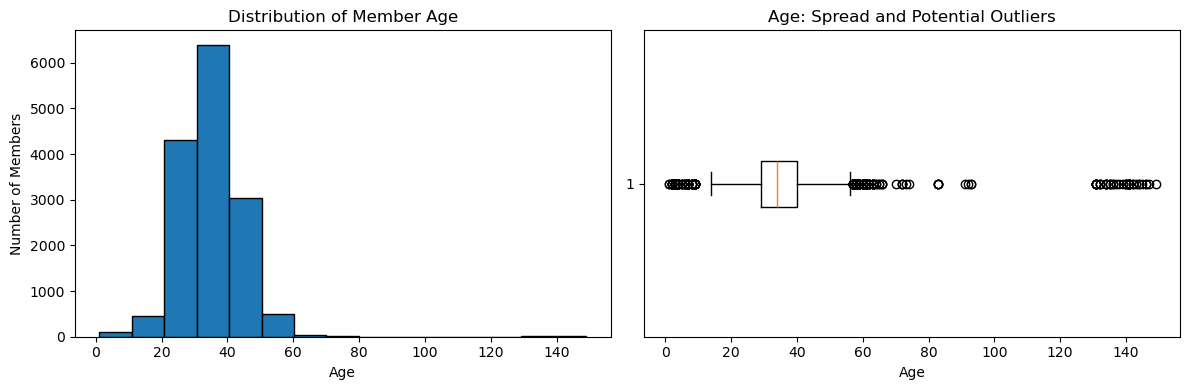

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['age'].dropna(), bins=15, edgecolor='black')
axes[0].set_title('Distribution of Member Age')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Number of Members')

axes[1].boxplot(df['age'].dropna(), vert=False)
axes[1].set_title('Age: Spread and Potential Outliers')
axes[1].set_xlabel('Age')

plt.tight_layout()
plt.show()

## 2. Membership plan distribution

The membership tier is a direct indicator of the type and intensity of service purchased. Ordering the plans from the least to the most extensive makes the distribution easier to interpret and helps reveal whether the customer base is concentrated in entry-level plans or spread across different service levels.

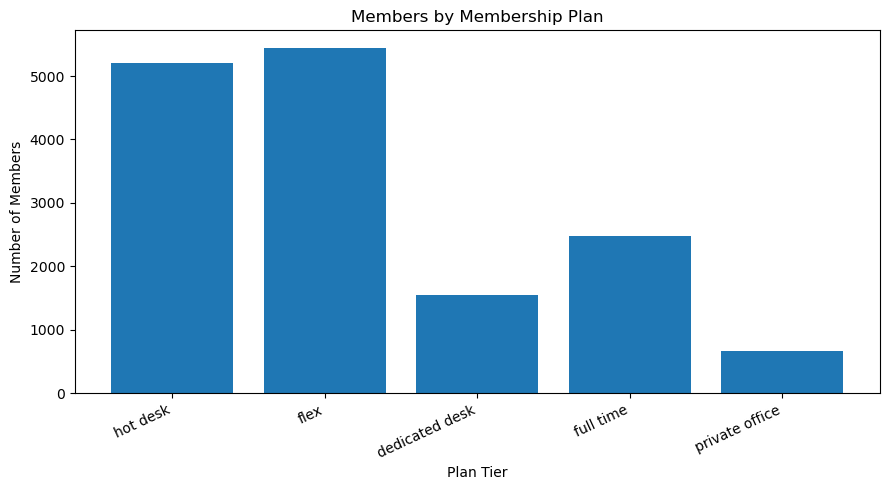

In [ ]:
plan_order = ['hot desk', 'flex', 'dedicated desk', 'full time', 'private office']
plan_counts = df['plan_tier'].value_counts().reindex(plan_order).dropna()

plt.figure(figsize=(9, 5))
plt.bar(plan_counts.index, plan_counts.values)
plt.title('Members by Membership Plan')
plt.xlabel('Plan Tier')
plt.ylabel('Number of Members')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

## 3. Lifetime value by membership plan

Lifetime value measures the economic contribution of each member over the full membership relationship. Comparing it across plan tiers shows whether more extensive plans are generally associated with greater customer value and whether substantial variation exists within the same tier. The boxplot is useful here because it displays the median, spread and potential high-value outliers without hiding the variation behind a single average.

In [ ]:
plot_data = [
    acdc_dataset.loc[df['plan_tier'] == plan, 'lifetime_value'].dropna()
    for plan in plan_order
]
valid_plans = [plan for plan, values in zip(plan_order, plot_data) if len(values) > 0]
valid_data = [values for values in plot_data if len(values) > 0]

plt.figure(figsize=(10, 5))
plt.boxplot(valid_data, tick_labels=valid_plans, showfliers=True)
plt.title('Lifetime Value by Membership Plan')
plt.xlabel('Plan Tier')
plt.ylabel('Lifetime Value (€)')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

NameError: name 'plan_order' is not defined

## 4. Member activity

Average weekly visits captures the regular intensity of workspace use and is more comparable across members than total visits alone, since memberships may have different durations. The distribution can reveal whether most customers use the space occasionally or frequently, and whether a smaller group behaves very differently from the majority.

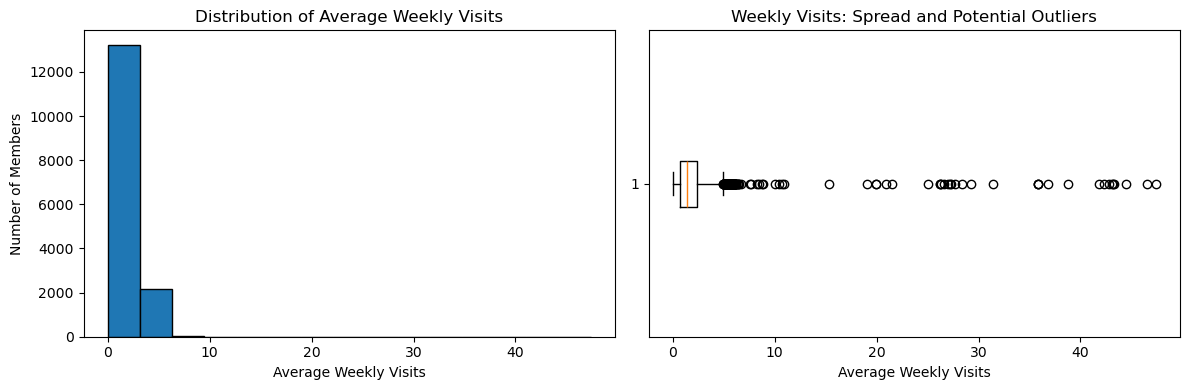

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['avg_weekly_visits'].dropna(), bins=15, edgecolor='black')
axes[0].set_title('Distribution of Average Weekly Visits')
axes[0].set_xlabel('Average Weekly Visits')
axes[0].set_ylabel('Number of Members')

axes[1].boxplot(df['avg_weekly_visits'].dropna(), vert=False)
axes[1].set_title('Weekly Visits: Spread and Potential Outliers')
axes[1].set_xlabel('Average Weekly Visits')

plt.tight_layout()
plt.show()

## 5. Feature engineering: recent plan utilization

Recent plan utilization compares the number of visits actually made with the number included in the member's plan during the last period. A value of 1 represents full use of the available entitlement, while lower values represent unused capacity.

The executed data show an average utilization rate of approximately 0.52, with the middle 50% of members ranging from about 0.24 to 0.80. This indicates substantial variation in how fully members use the access they purchase and makes utilization a useful behavioral measure for later segmentation. Members with zero entitlement are left undefined to avoid creating an artificial ratio.


In [ ]:
df['visit_utilization_rate'] = np.where(
    df['entitled_visits_last_period'] > 0,
    df['actual_visits_last_period'] / df['entitled_visits_last_period'],
    np.nan
)

df[['entitled_visits_last_period', 'actual_visits_last_period', 'visit_utilization_rate']].describe().T

,count,mean,std,min,25%,50%,75%,max
entitled_visits_last_period,15450.0,27.512777,13.478105,0.0,17.390000,26.090000,43.480000,78.27
actual_visits_last_period,15450.0,13.799159,11.385574,0.0,5.000000,10.000000,20.000000,60.00
visit_utilization_rate,15440.0,0.517532,0.312207,0.0,0.238996,0.517539,0.804906,1.00


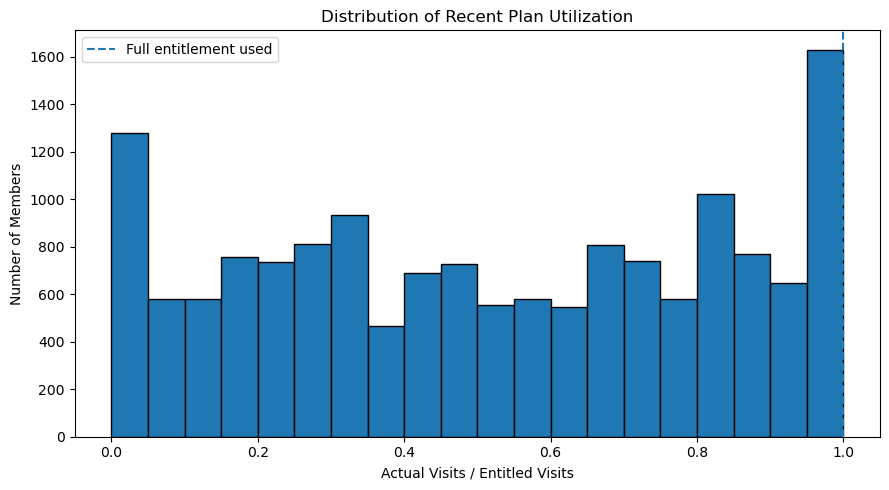

In [ ]:
utilization = df['visit_utilization_rate'].replace([np.inf, -np.inf], np.nan).dropna()

plt.figure(figsize=(9, 5))
plt.hist(utilization, bins=20, edgecolor='black')
plt.axvline(1, linestyle='--', linewidth=1.5, label='Full entitlement used')
plt.title('Distribution of Recent Plan Utilization')
plt.xlabel('Actual Visits / Entitled Visits')
plt.ylabel('Number of Members')
plt.legend()
plt.tight_layout()
plt.show()

## 6. Actual versus entitled visits

The scatter plot compares purchased access with actual attendance at member level. The diagonal represents full use of the available entitlement. Observations farther below the line correspond to greater under-utilization, while observations closer to the line indicate stronger use of the purchased plan.

Together with the utilization-rate distribution, this comparison shows that plan entitlement alone does not describe member behavior: customers with similar access levels can display substantially different attendance patterns.


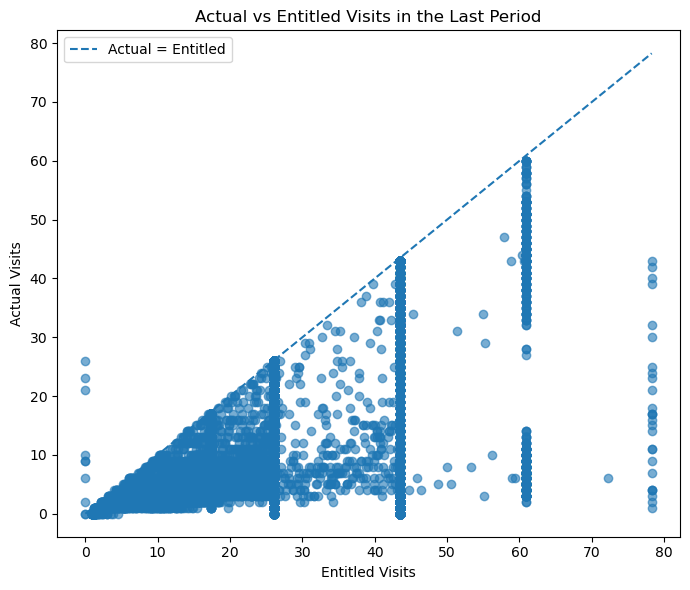

In [ ]:
visit_comparison = df[['entitled_visits_last_period', 'actual_visits_last_period']].dropna()

plt.figure(figsize=(7, 6))
plt.scatter(
    visit_comparison['entitled_visits_last_period'],
    visit_comparison['actual_visits_last_period'],
    alpha=0.6
)

max_value = visit_comparison.max().max()
plt.plot([0, max_value], [0, max_value], linestyle='--', label='Actual = Entitled')
plt.title('Actual vs Entitled Visits in the Last Period')
plt.xlabel('Entitled Visits')
plt.ylabel('Actual Visits')
plt.legend()
plt.tight_layout()
plt.show()

## 7. Relationship between activity and customer value

A high number of visits does not necessarily imply high economic value. Plotting average weekly visits against lifetime value allows both dimensions to be examined together. Members in different parts of the chart may represent distinct profiles: for example, high-value intensive users, high-value members with moderate attendance, or frequent users with comparatively low lifetime value.

The purpose at this stage is to identify structure and unusual observations rather than assign clusters in advance.

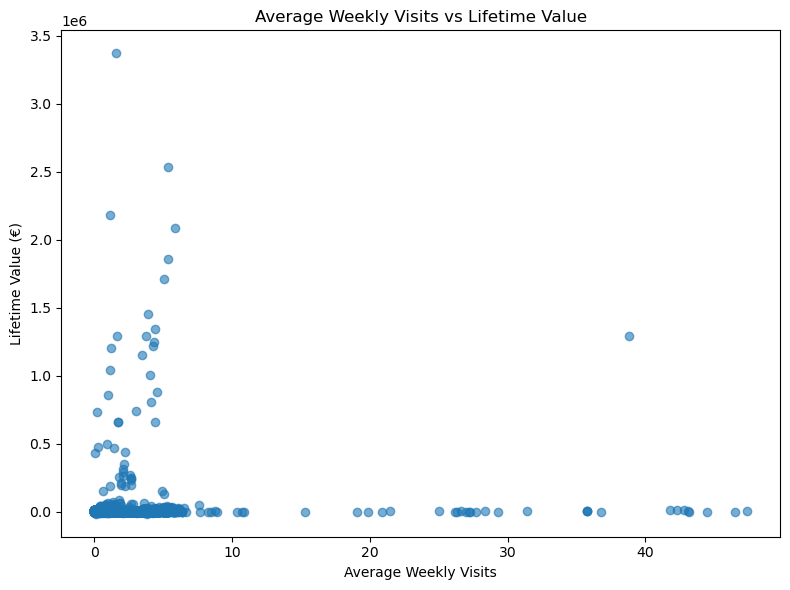

In [ ]:
value_activity = df[['avg_weekly_visits', 'lifetime_value']].dropna()

plt.figure(figsize=(8, 6))
plt.scatter(
    value_activity['avg_weekly_visits'],
    value_activity['lifetime_value'],
    alpha=0.6
)
plt.title('Average Weekly Visits vs Lifetime Value')
plt.xlabel('Average Weekly Visits')
plt.ylabel('Lifetime Value (€)')
plt.tight_layout()
plt.show()

## 8. Use of additional services

Coworking members can differ not only in how often they visit, but also in the services they use while on site. The chart below compares the share of members using each available add-on. These variables may help distinguish members who mainly require desk access from those who make broader use of meeting, event, communication or storage facilities.

Before calculating the percentages, the fields are converted consistently to boolean values. Missing or unrecognized values remain missing so they are not silently counted as either users or non-users.

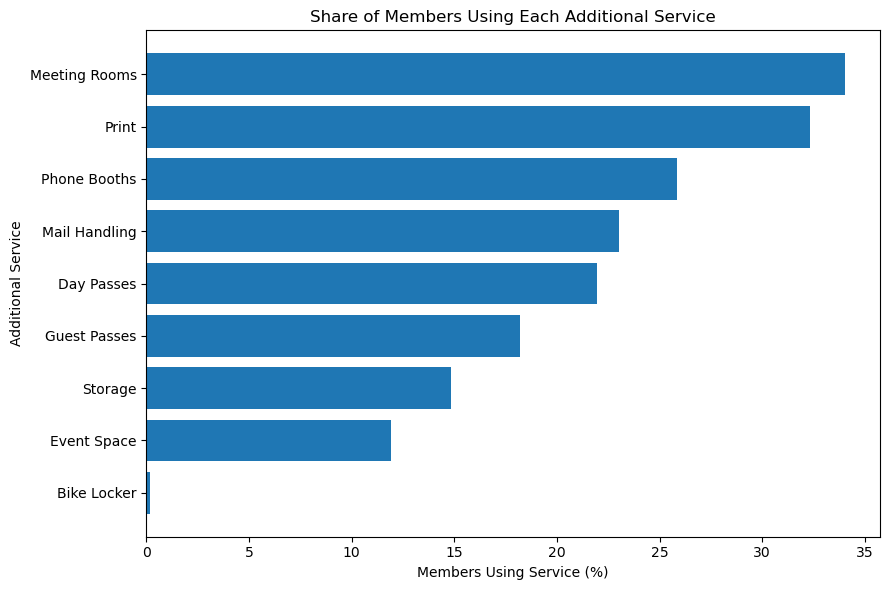

In [ ]:
addon_columns = [
    'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes',
    'uses_print', 'uses_mail_handling', 'uses_phone_booths',
    'uses_day_passes', 'uses_storage', 'uses_bike_locker'
]

def normalize_boolean(series):
    if pd.api.types.is_bool_dtype(series):
        return series.astype('boolean')
    mapping = {
        'true': True, '1': True, 'yes': True, 'y': True,
        'false': False, '0': False, 'no': False, 'n': False
    }
    return series.astype(str).str.strip().str.lower().map(mapping).astype('boolean')

for col in addon_columns:
    df[col] = normalize_boolean(df[col])

addon_usage = (df[addon_columns].mean() * 100).sort_values(ascending=True)
addon_labels = [label.replace('uses_', '').replace('_', ' ').title() for label in addon_usage.index]

plt.figure(figsize=(9, 6))
plt.barh(addon_labels, addon_usage.values)
plt.title('Share of Members Using Each Additional Service')
plt.xlabel('Members Using Service (%)')
plt.ylabel('Additional Service')
plt.tight_layout()
plt.show()

## 9. Team accounts versus individual accounts

Team and individual memberships may represent different commercial relationships. Comparing their lifetime value and weekly activity helps determine whether account type is likely to be useful for segmentation. Large differences would suggest that organizational customers and individual members should not automatically be treated as behaviorally equivalent.

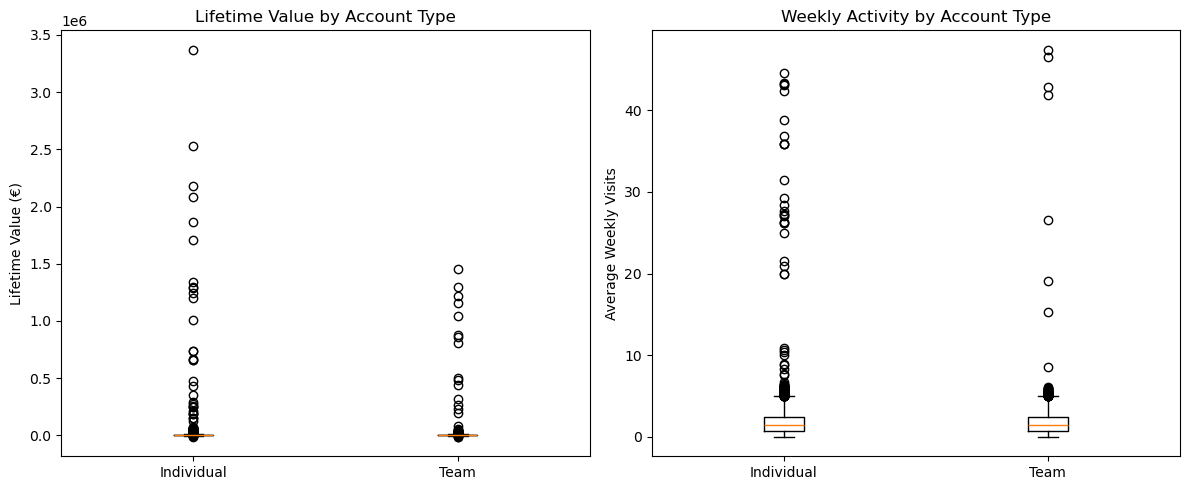

In [ ]:
team_labels = {False: 'Individual', True: 'Team'}
team_series = normalize_boolean(df['is_team_account'])

comparison_df = df[['lifetime_value', 'avg_weekly_visits']].copy()
comparison_df['account_type'] = team_series.map(team_labels)
comparison_df = comparison_df.dropna(subset=['account_type'])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

value_groups = [
    comparison_df.loc[comparison_df['account_type'] == label, 'lifetime_value'].dropna()
    for label in ['Individual', 'Team']
]
axes[0].boxplot(value_groups, tick_labels=['Individual', 'Team'])
axes[0].set_title('Lifetime Value by Account Type')
axes[0].set_ylabel('Lifetime Value (€)')

visit_groups = [
    comparison_df.loc[comparison_df['account_type'] == label, 'avg_weekly_visits'].dropna()
    for label in ['Individual', 'Team']
]
axes[1].boxplot(visit_groups, tick_labels=['Individual', 'Team'])
axes[1].set_title('Weekly Activity by Account Type')
axes[1].set_ylabel('Average Weekly Visits')

plt.tight_layout()
plt.show()

## 10. Correlation between numerical segmentation variables

The correlation matrix provides a compact view of how the main numerical variables move together. Strong positive correlations may indicate that two variables capture similar aspects of member behavior, while weak correlations suggest that they contribute different information.

This is relevant before clustering because including several near-duplicate measures can give one behavioral dimension too much influence. Correlation alone does not determine which variables should be kept, but it helps identify relationships that deserve closer inspection.

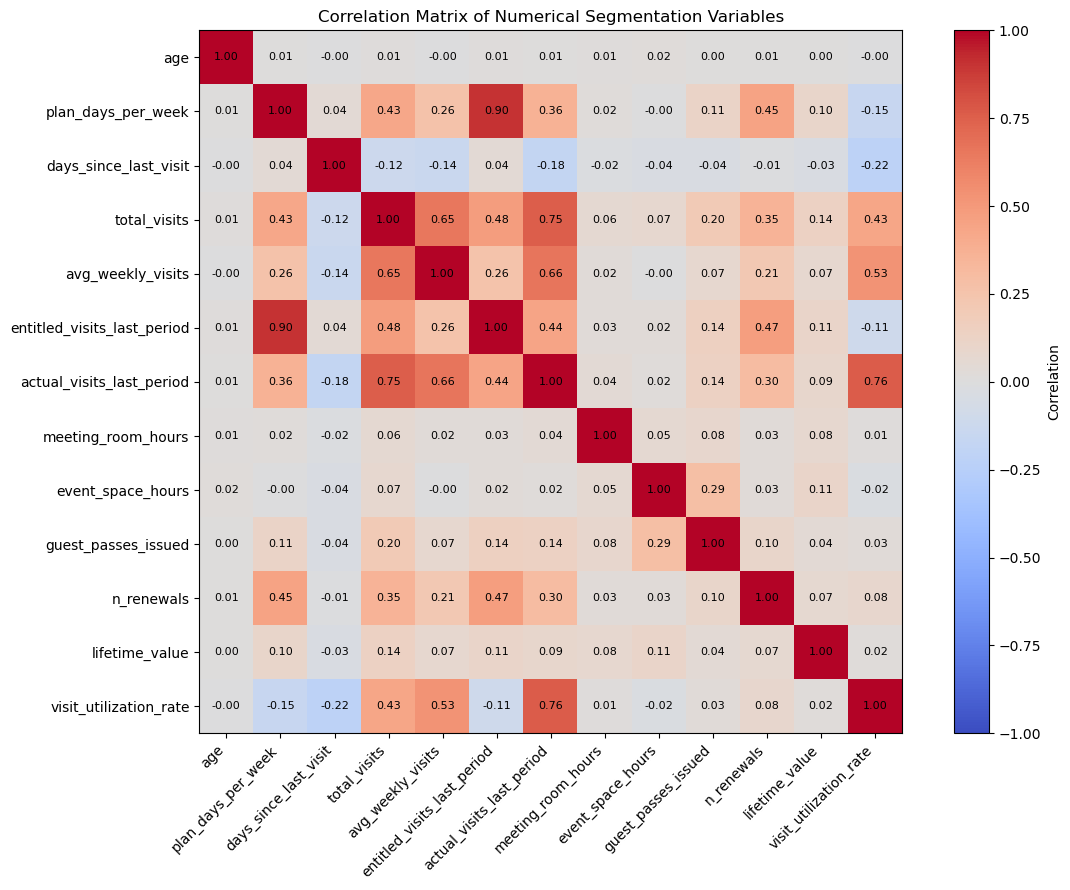

In [ ]:
corr_columns = [
    'age', 'plan_days_per_week', 'days_since_last_visit', 'total_visits',
    'avg_weekly_visits', 'entitled_visits_last_period', 'actual_visits_last_period',
    'meeting_room_hours', 'event_space_hours', 'guest_passes_issued',
    'n_renewals', 'lifetime_value', 'visit_utilization_rate'
]

corr_columns = [col for col in corr_columns if col in df.columns]
corr_matrix = df[corr_columns].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.columns)))
ax.set_xticklabels(corr_matrix.columns, rotation=45, ha='right')
ax.set_yticklabels(corr_matrix.columns)

for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        value = corr_matrix.iloc[i, j]
        if not np.isnan(value):
            ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=8)

fig.colorbar(im, ax=ax, label='Correlation')
ax.set_title('Correlation Matrix of Numerical Segmentation Variables')
plt.tight_layout()
plt.show()

## 11. Additional engineered features for later segmentation

Two additional variables summarize information that is otherwise spread across several fields. `addon_count` records how many different additional services each member uses, providing a simple measure of breadth of engagement with the coworking space. `membership_duration_days` measures the length of completed memberships where a valid start and end date are available.

Membership end dates that occur before the corresponding start date are treated as invalid rather than converted into negative durations. This avoids allowing placeholder or inconsistent dates to distort the engineered feature. These variables can later be evaluated alongside the original features for redundancy, missingness and relevance to segmentation.


In [ ]:
df['addon_count'] = df[addon_columns].sum(axis=1, min_count=1)

# Duration is calculated only for memberships with a valid start and end date.
df['membership_duration_days'] = (
    df['membership_end'] - df['membership_start']
).dt.days

# Final validation: a membership duration cannot be negative.
assert (df['membership_duration_days'].dropna() >= 0).all(),     "Negative membership durations remain after date cleaning."

df[['visit_utilization_rate', 'addon_count', 'membership_duration_days']].describe().T


,count,mean,std,min,25%,50%,75%,max
visit_utilization_rate,15440.0,0.517532,0.312207,0.0,0.238996,0.517539,0.804906,1.0
addon_count,15450.0,1.822783,1.50432,0.0,1.0,1.0,3.0,8.0
membership_duration_days,10891.0,328.448995,289.69174,3.0,69.0,249.0,535.0,1095.0


## 12. Preliminary implications for segmentation

The exploratory analysis points to several complementary dimensions of the customer relationship. Economic value is represented by lifetime value and renewals; usage intensity by weekly and recent visits; plan fit by recent utilization; and service engagement by the range of additional facilities used. Membership tier and account type provide further commercial context.

Recent plan utilization is particularly informative because members differ considerably in how much of their purchased access they actually use. The comparison between entitlement and attendance also suggests that customers with similar plans should not automatically be treated as behaviorally equivalent. Value, attendance and add-on engagement therefore provide distinct perspectives that can be combined in the later segmentation stage.

The main data issues to carry forward are missing values, skewed monetary and usage variables, extreme observations, and correlations between related visit measures. Date inconsistencies also require explicit treatment: invalid membership end dates are kept as missing rather than used to calculate misleading membership durations. These points should be considered when selecting, transforming and scaling variables for clustering.
